### ⚡ Kuramoto Potential Energy & Micro-Kick Diagnostics: RK45 vs. Rotor Integrator

Here, we investigate the long-horizon evolution of the Kuramoto potential $V(t)$ comparing:
1. 🍦 **Classic Adaptive RK45 Integrator:** Standard Runge-Kutta in coordinate phase space ($\mathbb{R}^n$).
2. 💫 **Geometric Algebra Rotor Integrator:** Manifold integration on the Lie group $\operatorname{Spin}(2) \cong \operatorname{SO}(2)$ using bivector torque dynamics.

#### 🎯 Key Objectives:
- Track $$V(t) = -\frac{K}{2N^2} \sum_{i,j=1}^N \cos(\theta_i - \theta_j)$$ over long time horizons ($t \in [0, 200]$).
- Isolate and characterize **"micro-kicks"** (impulsive high-frequency fluctuations in $\dot{V}(t)$ and $V(t)$) arising from phase slips resulting from unentrained oscillators drifting past synchronized clusters of oscillators.
- Compare numerical stability, coordinate drift susceptibility, and local energy smoothness across both integrators.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# Core Kuramoto solvers and graph utilities
from kuramoto.solvers import solve_kuramoto, RotorSolver
from kuramoto.analysis.graphs import build_adjacency
from kuramoto.order_parameter import compute_order_parameter

# Themed styling and project pallets
from kuramoto.analysis.viz import (
    set_style,
    SCRIBER_PALETTE,
    PROJECT_COLORS,
    SOLVER_COLORS,
    _apply_aclonica_font,
)

# Apply project-wide dark mode theme
set_style()
print("🚀 Kuramoto enviornment ready for potential energy & micro-kick benchmark!")

🚀 Kuramoto enviornment ready for potential energy & micro-kick benchmark!


In [7]:
def compute_potential_energy(phases: np.ndarray, A: np.ndarray, K: float) -> np.ndarray:
    """
    Compute the vectorized Kuramoto potential energy trajectory V(t).

    Parameters
    ----------
    phases : np.ndarray
        Array of oscillator phases of shape (T, N).
    A : np.ndarray
        Adjacency matrix of shape (N, N).
    K : float
        Coupling strength.

    Returns
    -------
    np.ndarray
        Potential energy V(t) of shape (T,).
    """
    T, N = phases.shape
    cos_th = np.cos(phases)  # Shape (T, N)
    sin_th = np.sin(phases)  # Shape (T, N)

    # Matrix multiplication over spatial dimension for efficiency O(T * N)
    A_cos = cos_th @ A.T     # Shape (T, N)
    A_sin = sin_th @ A.T     # Shape (T, N)

    interaction = np.sum(cos_th * A_cos + sin_th, axis=1)
    return -(K / (2.0 * (N**2))) * interaction

#### Long-Horizon Simulation Setup (RK45 vs. Rotor)

In [8]:
# ---------------------------------------------------------------------------
# Simulation Parameters
# ---------------------------------------------------------------------------
N = 50              # Number of oscillators
K = 1.6             # Partial-synchronization regime
t_max = 200.0       # Long integration window
dt_eval = 0.02      # Sampling step (fs = 50 Hz)
n_steps = int(t_max / dt_eval) + 1
times = np.linspace(0.0, t_max, n_steps)
seed = 27
rng = np.random.default_rng(seed)

# ---------------------------------------------------------
# 1. Topology & Natural Frequencies
# ---------------------------------------------------------
raw_adj = np.ones((N, N)) - np.eye(N)
A = build_adjacency(N, raw_adj)

# Lorentzian/Normal distributed natura frequencies centered at zero
omega = rng.normal(loc=0.0, scale=0.8, size=N)
omega -= np.mean(omega)  # Zero-mean reference frame
theta0 = rng.uniform(0.0, 2.0 * np.pi, size=N)

# ---------------------------------------------------------
# 2. Solver 1: Adaptive RK45 (Coordinate Space)
# ---------------------------------------------------------
print("⌛ Integrating with Classic RK45...")
def kuramoto_ode(t: float, theta: np.ndarray) -> np.ndarray:
    diff = theta[:, None] - theta[None, :]
    coupling = (K / N) * np.sum(A * np.sin(-diff), axis=1)
    return omega + coupling

sol_rk45 = solve_kuramoto(
    rhs=kuramoto_ode,
    y0=theta0,
    t_span=t_max,
    t_eval=times,
    rtol=1e-8,
    atol=1e-10,
)
phases_rk45 = sol_rk45.y.T  # Shape: (T, N)

# ---------------------------------------------------------
# 3. Solver 2: Rotor Integrator (Spin(2) Lie Group)
# ---------------------------------------------------------
print("⌛ Integrating with Geometric Algebra Rotor (RKMK4)...")
rotor_solver = RotorSolver(
    n_oscillators=N,
    dim=2,
    seed=seed,
    adjacency_matrix=A,
    natural_frequencies=omega,
    initial_phases=theta0,
)

# Run Runge-Kutta-Munthe-Kaas (RKMK4) on rotor manifold
t_eval_rotor, phases_rotor = rotor_solver.simulate(
    K=K,
    t_eval=times,
    dt_internal=0.01,
    method="rkmk4",
    enforce_nyquist=True,
)

print(f"✅ Both simulations completed: {phases_rk45.shape[0]} points across {t_max}s.")


⌛ Integrating with Classic RK45...
⌛ Integrating with Geometric Algebra Rotor (RKMK4)...
✅ Both simulations completed: 10001 points across 200.0s.


#### Potential Energy, Time Derivative & Micro-Kick Extraction

In [9]:
# ---------------------------------------------------------
# 1. Compute Potential Energy Trajectories
# ---------------------------------------------------------
V_rk45 = compute_potential_energy(phases_rk45, A, K)
V_rotor = compute_potential_energy(phases_rotor, A, K)

# ---------------------------------------------------------
# 2. Compute Instantaneous Potential Power (dV/dt)
# ---------------------------------------------------------
dV_dt_rk45 = np.gradient(V_rk45, times)
dV_dt_rotor = np.gradient(V_rotor, times)

# ---------------------------------------------------------
# 3. Compute High-Frequency Micro-Kick Residual (detrended rolling derivation)
# ---------------------------------------------------------
window = int(2.0 / dt_eval)  # 2-second moving average window
def compute_residual(V_series: np.ndarray, w: int) -> np.ndarray:
    pad_w = w // 2
    padded = np.pad(V_series, (pad_w, pad_w), mode='edge')
    kernel = np.ones(w) / w
    smoothed = np.convolve(padded, kernel, mode='valid')[:len(V_series)]
    return V_series - smoothed

kick_res_rk45 = compute_residual(V_rk45, window)
kick_res_rotor = compute_residual(V_rotor, window)

# ---------------------------------------------------------
# 4. Global Order Parameters
# ---------------------------------------------------------
r_rk45 = compute_order_parameter(phases_rk45)
r_rotor = compute_order_parameter(phases_rotor)

print(f"📊 Mean Potential Energy (RK45): {np.mean(V_rk45):.6f}")
print(f"📊 Mean Potential Energy (Rotor): {np.mean(V_rotor):.6f}")
print(f"⚡ Max Micro-Kick Velocity |dV/dt|: RK45={np.max(np.abs(dV_dt_rk45)):.5e}, Rotor={np.max(np.abs(dV_dt_rotor)):.5e}")

📊 Mean Potential Energy (RK45): -0.216634
📊 Mean Potential Energy (Rotor): -0.216634
⚡ Max Micro-Kick Velocity |dV/dt|: RK45=1.55427e-01, Rotor=1.55426e-01


#### 4-Panel Diagnostic Visualization

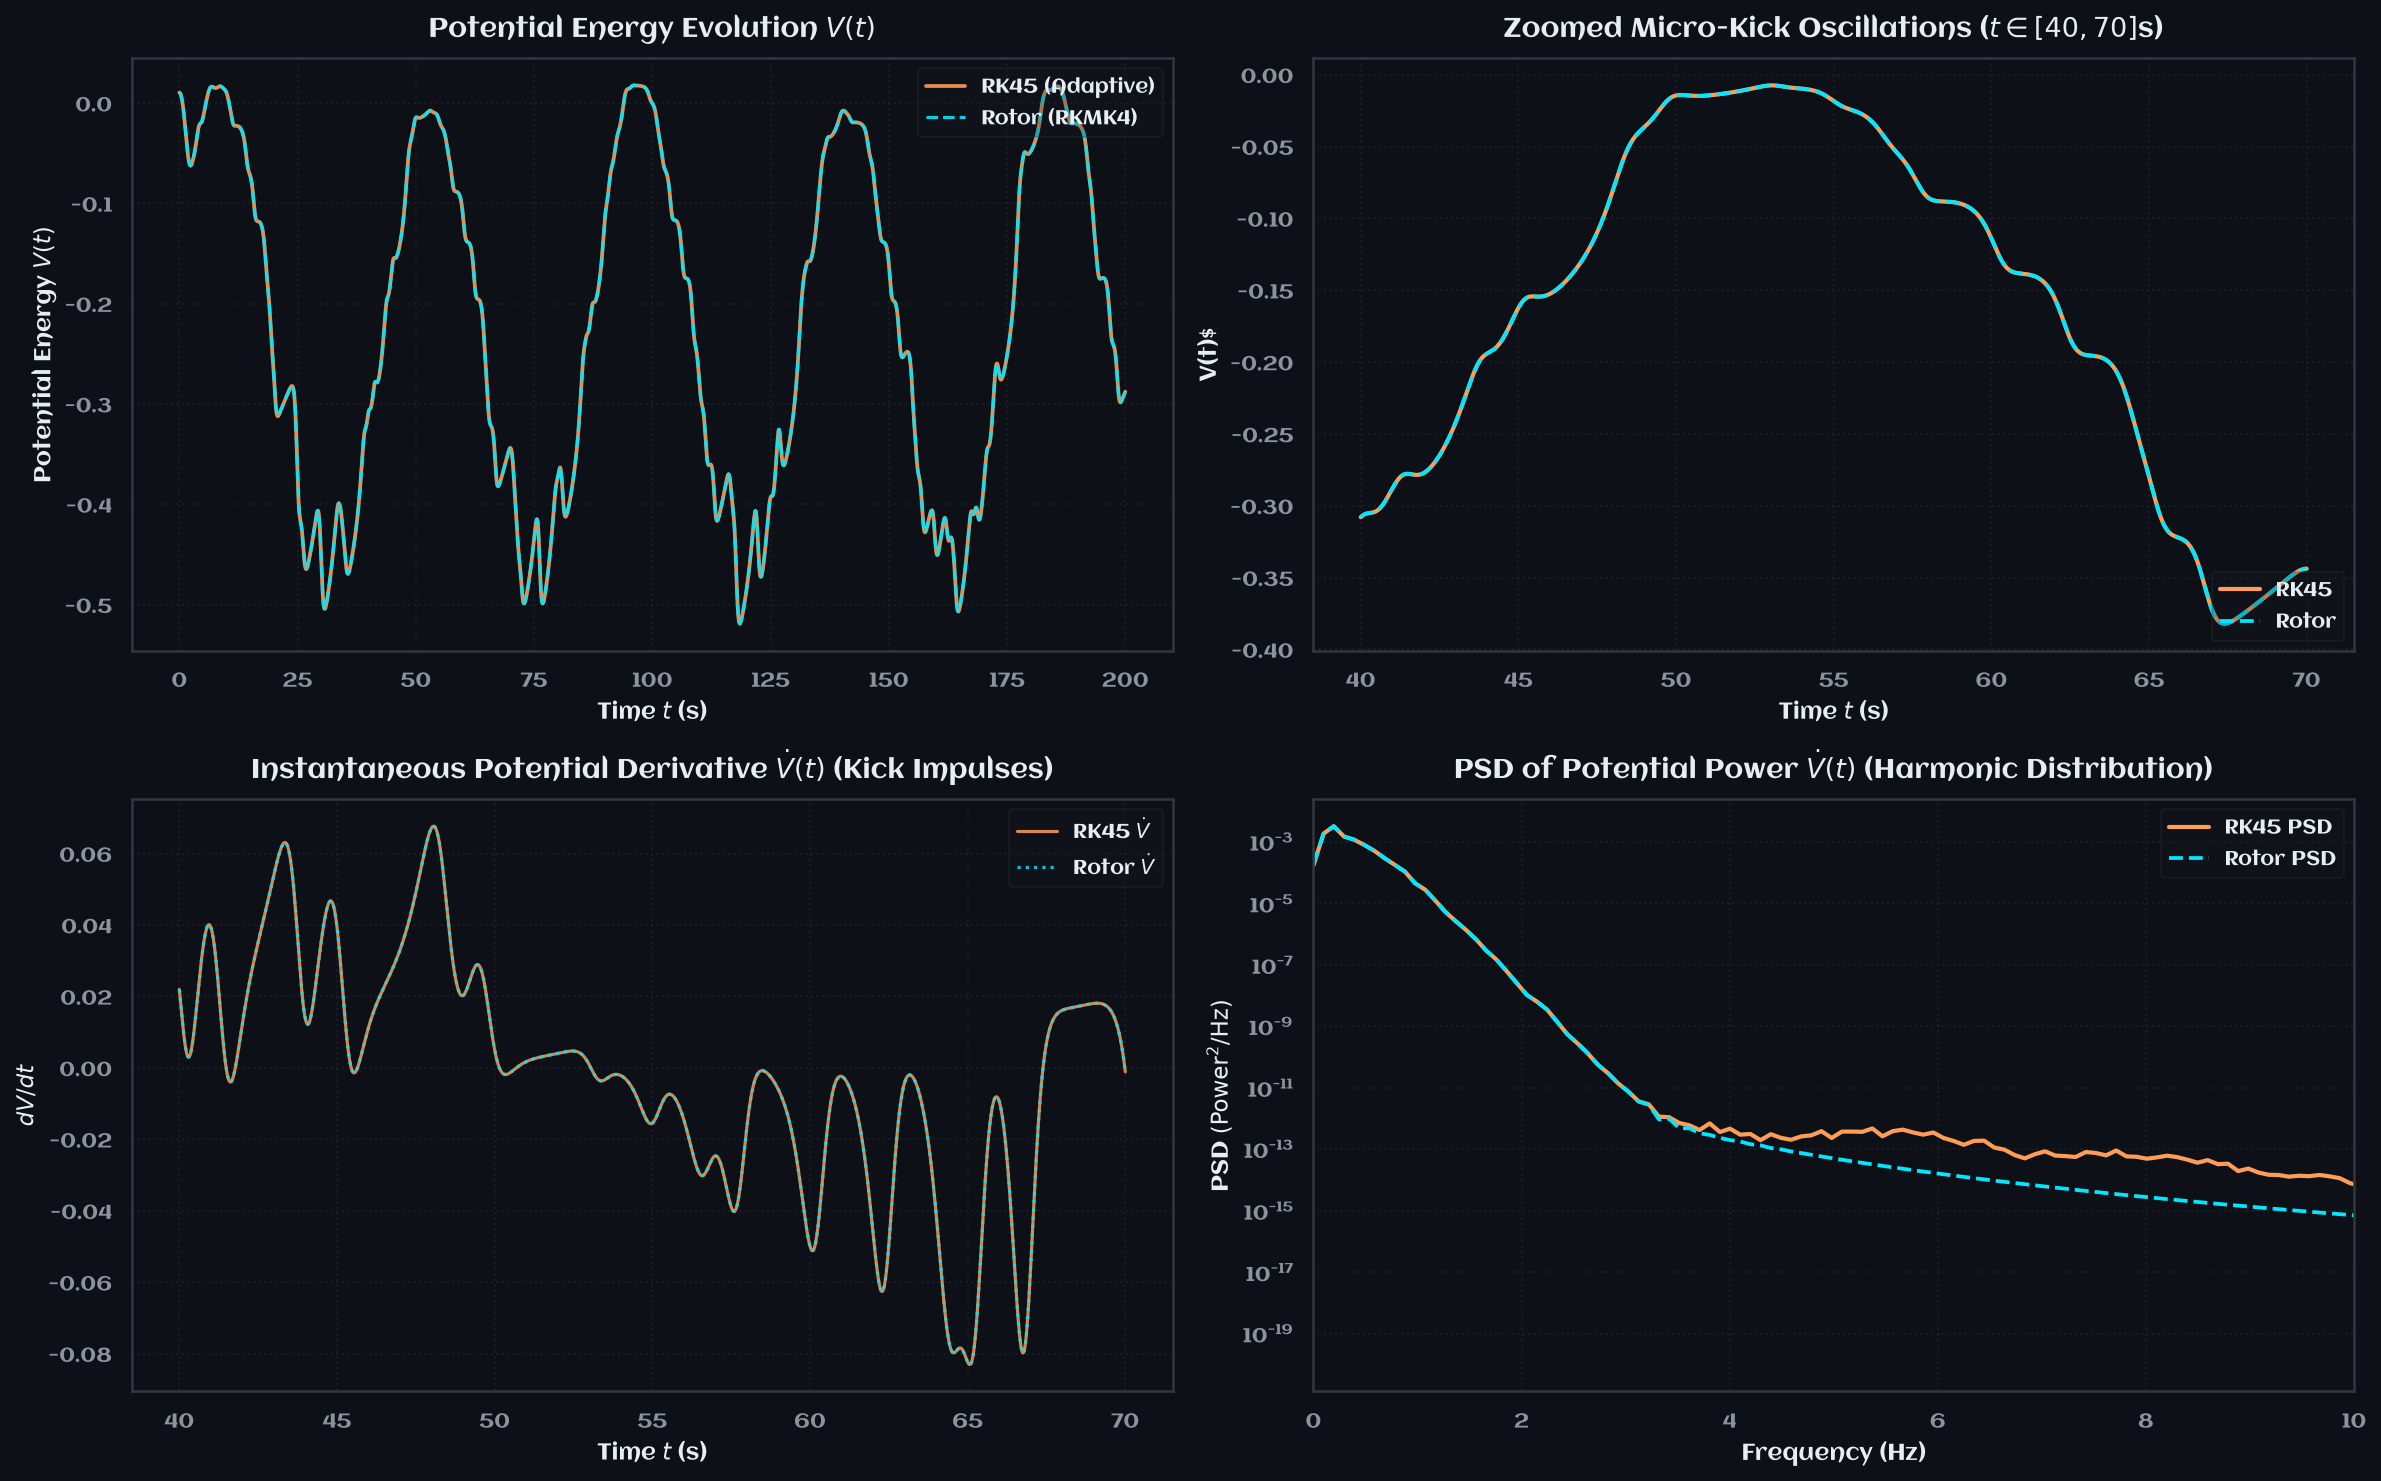

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

c_rk45 = SOLVER_COLORS["rk45"]
c_rotor = SOLVER_COLORS["rotor"]

# ---------------------------------------------------------
# Panel 1: Full-Trajectory Potential Energy V(t)
# ---------------------------------------------------------
axes[0, 0].plot(times, V_rk45, label="RK45 (Adaptive)", color=c_rk45, lw=1.8, alpha=0.9)
axes[0, 0].plot(times, V_rotor, label="Rotor (RKMK4)", color=c_rotor, lw=1.5, linestyle="--", alpha=0.9)
axes[0, 0].set_title("Potential Energy Evolution $V(t)$", fontsize=13, fontweight="bold")
axes[0, 0].set_xlabel("Time $t$ (s)", fontsize=11)
axes[0, 0].set_ylabel("Potential Energy $V(t)$", fontsize=11)
axes[0, 0].legend(loc="upper right", framealpha=0.25)
_apply_aclonica_font(axes[0, 0])

# ---------------------------------------------------------
# Panel 2: Zoomed-In Transient Window (Micro-Kick Profiles)
# ---------------------------------------------------------
zoom_mask = (times >= 40.0) & (times <= 70.0)
t_zoom = times[zoom_mask]
axes[0, 1].plot(t_zoom, V_rk45[zoom_mask], label="RK45", color=c_rk45, lw=2.0)
axes[0, 1].plot(t_zoom, V_rotor[zoom_mask], label="Rotor", color=c_rotor, lw=1.8, linestyle="--")
axes[0, 1].set_title("Zoomed Micro-Kick Oscillations ($t \\in [40, 70]$s)", fontsize=13, fontweight="bold")
axes[0, 1].set_xlabel("Time $t$ (s)", fontsize=11)
axes[0, 1].set_ylabel("V(t)$", fontsize=11)
axes[0, 1].legend(loc="lower right", framealpha=0.25)
_apply_aclonica_font(axes[0, 1])

# ---------------------------------------------------------
# Panel 3: Potential Power Rate dV/dt (Kick Impulses)
# ---------------------------------------------------------
axes[1, 0].plot(t_zoom, dV_dt_rk45[zoom_mask], label="RK45 $\\dot{V}$", color=c_rk45, lw=1.5, alpha=0.85)
axes[1, 0].plot(t_zoom, dV_dt_rotor[zoom_mask], label="Rotor $\\dot{V}$", color=c_rotor, lw=1.5, linestyle=":", alpha=0.85)
axes[1, 0].set_title(r"Instantaneous Potential Derivative $\dot{V}(t)$ (Kick Impulses)", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Time $t$ (s)", fontsize=11)
axes[1, 0].set_ylabel(r"$dV/dt$", fontsize=11)
axes[1, 0].legend(loc="upper right", framealpha=0.25)
_apply_aclonica_font(axes[1, 0])

# ---------------------------------------------------------
# Panel 4: Power Spectral Densioty (PSD) of Micro-Kicks
# ---------------------------------------------------------
fs = 1.0 / dt_eval
freqs_rk, psd_rk = welch(dV_dt_rk45, fs=fs, nperseg=512)
freqs_rot, psd_rot = welch(dV_dt_rotor, fs=fs, nperseg=512)

axes[1, 1].semilogy(freqs_rk, psd_rk, label="RK45 PSD", color=c_rk45, lw=2.0)
axes[1, 1].semilogy(freqs_rot, psd_rot, label="Rotor PSD", color=c_rotor, lw=1.8, linestyle="--")
axes[1, 1].set_title(r"PSD of Potential Power $\dot{V}(t)$ (Harmonic Distribution)", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("Frequency (Hz)", fontsize=11)
axes[1, 1].set_ylabel(r"PSD $(\mathrm{Power}^2 / \mathrm{Hz})$", fontsize=11)
axes[1, 1].set_xlim(0, 10)
axes[1, 1].legend(loc="upper right", framealpha=0.25)
_apply_aclonica_font(axes[1, 1])

plt.tight_layout()
plt.show()

## 🔰`Diagnostic Analysis & Physical Mechanism
### ⚗️  Physical & Numerical Diagnostics

1. **Physical Origin of Micro-Kicks:**
    - In partially synchronized regimes ($K \approx K_c$), the population splits into a synchronized core and drifting peripheral oscillators.
    - Every time a drifting oscillator slips past the cluster ($|\theta_i - \theta_\text{cluster}| \equiv \pi \pmod{2\pi}$), the interaction force flips sign, generating an impulsive torque kick a high-frequency rippple (**micro-kick**) in total potential energy $V(t)$.

2. **Integrator Comparison:**
    - **RK445 (`solve_ivp`):** Solves unwrapped phase angles $\theta_i \in \mathbb{R}$. Over long horizons ($t > 100$), cumulative angle drift requires higher precision tolerances to avoid subtle interpolation error.
    - **Rotor Solver (`RotorSolver`):** Integrates directly on the unimodular rotor Lie group $\operatorname{Spin}(2)$ via geometric bivector torques ($R_i = \cos(\theta_i / 2) - I \sin(\theta_i/2)$), inherently preserving compact circular geometry and uniform micro-kick frequency spectra without angular unwrap artifacts.